# PyTorch basics

В этой тетрадке мы познакомимся с общими принципами построения нейронных сетей.

**Цели тетрадки**

1. Знакомство с базовыми слоями PyTorch
1. Практика в построении и обучении сетей

**(повтор) Материалы по pytorch:**

* [PyTorch docs](https://pytorch.org/docs/stable/index.html)
* [Классная статья про pytorch internal](http://blog.ezyang.com/2019/05/pytorch-internals/)

## Prerequirements

```
pip install torch torchvision numpy matplotlib
```

In [18]:
!pip install opencv-python-headless

   ---------------------------------------- 0.0/40.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.1 MB ? eta -:--:--
   ---------------------------------------- 0.1/40.1 MB 812.7 kB/s eta 0:00:50
   ---------------------------------------- 0.1/40.1 MB 901.1 kB/s eta 0:00:45
   ---------------------------------------- 0.2/40.1 MB 1.4 MB/s eta 0:00:28
   ---------------------------------------- 0.5/40.1 MB 2.4 MB/s eta 0:00:17
    --------------------------------------- 0.9/40.1 MB 3.4 MB/s eta 0:00:12
    --------------------------------------- 0.9/40.1 MB 3.4 MB/s eta 0:00:12
   - -------------------------------------- 1.9/40.1 MB 5.9 MB/s eta 0:00:07
   -- ------------------------------------- 2.1/40.1 MB 5.3 MB/s eta 0:00:08
   -- ------------------------------------- 2.6/40.1 MB 5.9 MB/s eta 0:00:07
   --- ------------------------------------ 3.1/40.1 MB 6.4 MB/s eta 0:00:06
   --- ------------------------------------ 3.6/40.1 MB 6.7 MB/s eta 0:00:06
   ---- -

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
catboost 1.2.7 requires numpy<2.0,>=1.16.0, but you have numpy 2.4.2 which is incompatible.
lightautoml 0.4.1 requires numpy<2.0.0, but you have numpy 2.4.2 which is incompatible.
lightautoml 0.4.1 requires numpy<2.0.0,>=1.22; python_version >= "3.10", but you have numpy 2.4.2 which is incompatible.
marginaleffects 0.0.14 requires scipy>=1.14.1, but you have scipy 1.12.0 which is incompatible.
numba 0.59.1 requires numpy<1.27,>=1.22, but you have numpy 2.4.2 which is incompatible.
pywavelets 1.5.0 requires numpy<2.0,>=1.22.4, but you have numpy 2.4.2 which is incompatible.
rectools 0.12.0 requires numpy<2.0.0,>=1.26; python_version == "3.12", but you have numpy 2.4.2 which is incompatible.
scipy 1.12.0 requires numpy<1.29.0,>=1.22.4, but you

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torch.optim as optim
from torchvision import transforms
from torchvision.datasets import MNIST

import matplotlib.pyplot as plt

## Hello MNIST

Прежде чем собирать сеть, давайте определим инстансы класса `Dataset`, которые будут возвращать примеры из тренировочной и валидационной выборок.  
С помощью ячейки ниже, мы скачаем датасет [MNIST](http://yann.lecun.com/exdb/mnist/) в текущую директорию и сможем получать примеры из соответствующих объектов.

In [5]:
transform_to_tensor = transforms.Compose([
    transforms.ToTensor()
])

mnist_train = MNIST(root='./', train=True, download=True, transform=transform_to_tensor)
mnist_val = MNIST(root='./', train=False, download=True, transform=transform_to_tensor)

100%|█████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:01<00:00, 5.98MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 239kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:01<00:00, 1.62MB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 4.60MB/s]


Посмотрим на несколько примеров из тренировочной выборки

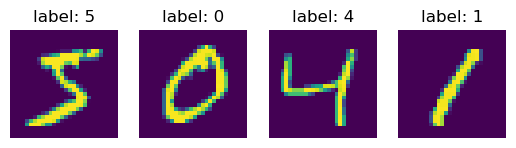

In [21]:
def show_examples(dataset: Dataset, num_examples: int = 4):
    fig, ax = plt.subplots(1, num_examples)

    for i in range(num_examples):
        img, label = dataset[i]
        ax[i].imshow(img[0])
        ax[i].set_title(f'label: {label}')
        ax[i].axis('off')
    plt.show()


show_examples(dataset=mnist_train)

## Задание 1
**(0.5 балла)** Напишите свою версию датасета, который будет читать картинки с диска.  
Подразумевается, что если вы написали свой датасет, то он будет использоваться при обучении вместо дефолтного `MNIST`.  

В ячейках ниже сгенерится датасет в таком формате:
- /MNIST_image_folder
    - /train.csv
    - /train/{class_name}/{image_name}.png
    - /val.csv
    - /val/{class_name}/{image_name}.png

CSV файлы содержат название файла и его лейбл: `image`, `label`.

*Hint 1:* нужно унаследоваться от класса `Dataset` и переопределить методы `__getitem__` и `__len__`.
Первый должен возвращать картинку и ее лейбл, а второй количество примеров в датасете.
(На самом деле второй метод не обязателен для самого датасета, но он необходим для
[семплера](https://pytorch.org/docs/stable/data.html#torch.utils.data.RandomSampler),
который используется даталоадером)
(см. [PyTorch docs](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset),
[PyTorch tutorual](https://pytorch.org/tutorials/recipes/recipes/custom_dataset_transforms_loader.html?highlight=dataset))  
*Hint 2:* для работы с картинками лучше использовать OpenCV: `pip install opencv-python-headless`.
В частности [cv2.imread](https://docs.opencv.org/master/d4/da8/group__imgcodecs.html#ga288b8b3da0892bd651fce07b3bbd3a56).  
*Hint 3:* обратите особое внимание на то, что возвращает функция `cv2.imread` (пример загрузки изображения с помощью cv2 есть в семе)


In [24]:
import pickle
import numpy as np
import os
import cv2
from collections import Counter
from tqdm.auto import tqdm
import pandas as pd

def generate_image_folder_dataset(dataset, target_path, csv_path):

    images_counter = Counter()

    files = []
    labels = []

    for image, label in tqdm(dataset):
        class_folder = target_path + "/" + str(label)
        if not os.path.exists(class_folder):
            os.makedirs(class_folder, exist_ok=True)

        images_counter[label] += 1
        file_name = f"/{images_counter[label]:05}.png"
        full_image_file_name = class_folder + file_name

        files.append(str(label) + file_name)
        labels.append(label)

        image = np.array(image)
        image = (image * 255).astype(np.uint8)
        image = np.transpose(image, [1, 2, 0])
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

        # print(image.dtype)
        # print(image.shape)
        cv2.imwrite(full_image_file_name, image)

        # break
    pd.DataFrame({ "image": files, "label": labels }).to_csv(csv_path, index=False)

generate_image_folder_dataset( mnist_train,  "./MNIST_image_folder/train", "MNIST_image_folder/train.csv" )
generate_image_folder_dataset( mnist_val,  "./MNIST_image_folder/val", "MNIST_image_folder/val.csv" )

  0%|          | 0/60000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

Теперь можно написать свой класс датасета для тех файлов, которые мы сгенерили

In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import cv2

class DatasetMNIST(Dataset):
    def __init__(self, root='./MNIST_image_folder', train=True, transform=None):
        self.root = root
        self.train = train
        self.transform = transform

        split = "train" if train else "val"
        self.split_dir = os.path.join(self.root, split)
        self.csv_path = os.path.join(self.root, f"{split}.csv")

        self.df = pd.read_csv(self.csv_path)
       
        self.df["label"] = self.df["label"].astype(int)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        rel_path = row["image"]
        label = int(row["label"])

        img_path = os.path.join(self.split_dir, rel_path)

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Can't read image: {img_path}")

        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # (28,28)

        if self.transform is not None:
            img = self.transform(img)  # torch.Tensor (1,28,28) float32 in [0,1]
        else:
            import torch
            img = torch.from_numpy(img).unsqueeze(0).float() / 255.0

        return {"image": img, "label": label}

тест класса датасета

In [28]:
def test_dataset(dataset, test_name=""):

    assert len(dataset) > 0, f"{test_name}: dataset length is greater then zero"

    idateset = iter(dataset)
    item = next(idateset)

    assert isinstance(item, dict), f"{test_name}: dataset returned dict"
    assert "image" in item, f"{test_name}: dataset item dict has image"
    assert "label" in item, f"{test_name}: dataset item dict has label"

    assert item['image'].shape == (1, 28, 28), f"{test_name}: dataset image shape is correct. Got: {item['image'].shape}"

mydataset = DatasetMNIST(train=False, transform=transform_to_tensor)
test_dataset(mydataset, test_name="val")

mydataset = DatasetMNIST(train=True, transform=transform_to_tensor)
test_dataset(mydataset, test_name="train")

## Задание 2
**(0.3 балла)** Напишите класс MLP сети из 3 линейных слоев, которая будет получать на вход
батч картинок размера [BS, C, H, W]

*Hint 1:* метод `.flatten(start_dim=1)` поможет вытянуть картинку в вектор.  
*Hint 2:* выход должен соответствовать количеству лейблов, то есть 10.  
*Hint 3:* пачка линейных слоев подряд не имеет смысла без нелинейностей между ними. Попробуйте разные слои нелинейности (один слой на один эксперимент): `ReLU`, `LeakyReLU`, `Tanh` ... [Другие](https://pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity)

In [30]:
# важно! все зависимости, которые используете (если добавляее новые) в этом классе надо явно продублировать в эту ячейку
import torch
import torch.nn as nn
import torch.nn.functional as F

class CustomMLP(nn.Module):
    def __init__(self,
                 num_pixels_per_img: int = 784,  # 28*28
                 hidden1: int = 256,
                 hidden2: int = 128,
                 ):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(num_pixels_per_img, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 10),
        )

    def forward(self, x):
        x = x.flatten(start_dim=1)
        logits = self.net(x)
        return logits  # [BS, 10]

    def compute_all(self, batch):
        """
        batch ожидается как dict:
          batch["image"]: [BS, 1, 28, 28]
          batch["label"]: [BS] (int64)
        """
        x = batch["image"]
        y = batch["label"]

        logits = self.forward(x)

        if not torch.is_tensor(y):
            y = torch.tensor(y, device=logits.device)
        y = y.long()

        loss = F.cross_entropy(logits, y)
        return logits, loss

## Задание 3
**(0.3 балла)** Напишите класс CNN сети из 3 сверточных слоев.

*Hint 1:* на вход все те же батчи размера [BS, C, H, W]  
*Hint 2:* описание сверточных слоев [PyTorch docs](https://pytorch.org/docs/stable/nn.html#convolution-layers). Нам нужен `Conv2d`

Тут тоже можете поэксперементировать с разными слоями активации.

Чтобы было проще считать размерности для конечного слоя, используйте `kernel_size=3, padding=1` в сверточных слоях

In [32]:
# важно! все зависимости, которые используете (если добавляее новые) в этом классе надо явно продублировать в эту ячейку
import torch
import torch.nn as nn
import torch.nn.functional as F

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2)

        self.fc = nn.Linear(64 * 7 * 7, 10)

    def forward(self, x):

        x = F.relu(self.conv1(x))
        x = self.pool(x)

        x = F.relu(self.conv2(x))
        x = self.pool(x)

        x = F.relu(self.conv3(x))

        x = x.flatten(start_dim=1)

        x = self.fc(x)

        return x

    def compute_all(self, batch):

        x = batch["image"]
        y = batch["label"]

        logits = self.forward(x)

        loss = F.cross_entropy(logits, y)

        return logits, loss

## Задание 4
**(0.3 балла)** Напишите класс CNN сети из 3 блоков с добавлением skip-connection блока
(ResNet [paper](https://arxiv.org/abs/1512.03385)).  
**(0.3 балла)** Реализовать residual блок в отдельном классе `ResBlock`.

*Hint 1:* на вход все те же батчи размера [BS, C, H, W]  
*Hint 2:* пример skip-connection:  
<img src="https://github.com/fintech-dl-hse/course/raw/refs/heads/main/seminars/04_cnn/static/skip_connection.png" width=400 />

In [34]:
# важно! все зависимости, которые используете (если добавляее новые) в этом классе надо явно продублировать в эту ячейку
import torch
import torch.nn as nn
import torch.nn.functional as F

class ResBlock(nn.Module):
    def __init__(self, in_dim, hidden_dim):
        super().__init__()
        """
        in_dim --- число каналов на входе и выходе блока
        hidden_dim --- число каналов внутри блока
        """
        self.conv1 = nn.Conv2d(in_dim, hidden_dim, kernel_size=3, padding=1, bias=False)
        self.conv2 = nn.Conv2d(hidden_dim, in_dim, kernel_size=3, padding=1, bias=False)

        self.bn1 = nn.BatchNorm2d(hidden_dim)
        self.bn2 = nn.BatchNorm2d(in_dim)

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + x             
        out = F.relu(out)
        return out


class CustomResNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 28x28 -> 14x14
        )

        self.blocks = nn.Sequential(
            ResBlock(in_dim=32, hidden_dim=64),
            ResBlock(in_dim=32, hidden_dim=64),
            ResBlock(in_dim=32, hidden_dim=64),
        )

        self.pool = nn.MaxPool2d(2)  # 14x14 -> 7x7
        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        x = self.pool(x)
        x = x.flatten(start_dim=1)
        logits = self.fc(x)
        return logits

    def compute_all(self, batch):
        x = batch["image"]
        y = batch["label"].long()

        logits = self.forward(x)
        loss = F.cross_entropy(logits, y)
        return logits, loss

## Задание 5
**(0.3 балла)** Инициализируйте и обучите сети из пунктов 1, 2, 3, используя класс `Trainer` из семинара.

В тренерене, возможно, вы захотите писать больше метрик: лосс во время трейна, валидационный лосс, валидационные метрики (можно префиксовать валидационные метрики с помощью "val", чтобы не путались)

Каждая модель должна побить определенные пороги кач-ва (> 0.8 за 3 эпохи)

In [36]:
import torch
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter

class Trainer:
    def __init__(self, model, optimizer, train_dataset, val_dataset, batch_size=128):
        self.model = model
        self.optimizer = optimizer
        self.batch_size = batch_size

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model.to(self.device)

        self.train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        self.val_loader = DataLoader(
            val_dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )

        self.writer = SummaryWriter()

        self.global_step = 0
        self.epoch = 0

    def _to_device(self, batch):
        # batch ожидается как dict: {"image": tensor, "label": int/tensor}
        x = batch["image"].to(self.device, non_blocking=True)
        y = batch["label"]
        if not torch.is_tensor(y):
            y = torch.tensor(y)
        y = y.to(self.device, non_blocking=True).long()
        return {"image": x, "label": y}

    @torch.no_grad()
    def evaluate(self):
        self.model.eval()

        total_loss = 0.0
        total_correct = 0
        total_count = 0

        for batch in self.val_loader:
            batch = self._to_device(batch)
            logits, loss = self.model.compute_all(batch)

            bs = batch["label"].shape[0]
            total_loss += loss.item() * bs

            preds = logits.argmax(dim=1)
            total_correct += (preds == batch["label"]).sum().item()
            total_count += bs

        avg_loss = total_loss / max(total_count, 1)
        acc = total_correct / max(total_count, 1)
        return avg_loss, acc

    def train(self, num_epochs):
        for _ in range(num_epochs):
            self.model.train()
            running_loss = 0.0
            running_count = 0

            for batch in self.train_loader:
                batch = self._to_device(batch)

                self.optimizer.zero_grad(set_to_none=True)

                logits, loss = self.model.compute_all(batch)
                loss.backward()
                self.optimizer.step()

                bs = batch["label"].shape[0]
                running_loss += loss.item() * bs
                running_count += bs

                # логируем train loss по шагам
                self.writer.add_scalar("train/loss_step", loss.item(), self.global_step)
                self.global_step += 1

            train_loss = running_loss / max(running_count, 1)

            val_loss, val_acc = self.evaluate()

            self.writer.add_scalar("train/loss", train_loss, self.epoch)
            self.writer.add_scalar("val/loss", val_loss, self.epoch)
            self.writer.add_scalar("val/acc", val_acc, self.epoch)

            print(
                f"Epoch {self.epoch+1}: "
                f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}"
            )

            self.epoch += 1

        self.writer.flush()

#### CustomMLP

In [38]:
model = CustomMLP()
opt = optim.SGD(model.parameters(), lr=3e-3)

mnist_train = DatasetMNIST(train=True, transform=transform_to_tensor)
mnist_val = DatasetMNIST(train=False, transform=transform_to_tensor)

trainer = Trainer(model, opt, mnist_train, mnist_val, batch_size=128)

In [ ]:
trainer.train(3)
torch.save(model.state_dict(), "custom_mlp.pt") # важно сохранить веса обученой модели!

#### CustomCNN

In [ ]:
model = CustomCNN()
opt = optim.SGD(model.parameters(), lr=3e-3)

mnist_train = DatasetMNIST(train=True, transform=transform_to_tensor)
mnist_val = DatasetMNIST(train=False, transform=transform_to_tensor)

trainer = Trainer(model, opt, mnist_train, mnist_val, batch_size=128)

In [ ]:
trainer.train(3)
torch.save(model.state_dict(), "custom_cnn.pt")  # важно сохранить веса обученой модели!

#### CustomResNet

In [ ]:
model = CustomResNet()
opt = optim.SGD(model.parameters(), lr=3e-3)

mnist_train = DatasetMNIST(train=True, transform=transform_to_tensor)
mnist_val = DatasetMNIST(train=False, transform=transform_to_tensor)

trainer = Trainer(model, opt, mnist_train, mnist_val, batch_size=128)

In [ ]:
    trainer.train(3)
    torch.save(model.state_dict(), "custom_resnet.pt") # важно сохранить веса обученой модели!

### Тест


In [ ]:
import pytest
import torch
import torch.nn as nn

import sys

from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import MNIST

transform_to_tensor = transforms.Compose([
    transforms.ToTensor()
])

mnist_val = MNIST(root='./', train=False, download=True, transform=transform_to_tensor)

def _test_model(model, target_accuracy, flatten=True):
    print(model)

    dataloader = DataLoader(mnist_val, batch_size=128)

    all_logits = []
    all_labels = []

    with torch.no_grad():

        for images, labels in dataloader:
            if flatten:
                images = images.flatten(1)
            logits = model(images)
            all_logits.append(logits)
            all_labels.append(labels)

        all_logits = torch.cat(all_logits)
        all_labels = torch.cat(all_labels)

        print(all_logits.shape, all_labels.shape)

        accuracy = (all_logits.argmax(axis=1) == all_labels).float().mean().cpu().numpy()
        print("accuracy", accuracy)

        assert accuracy > target_accuracy

def test_model_mlp():

    cmlp = CustomMLP()
    cmlp.load_state_dict( torch.load("custom_mlp.pt") )
    cmlp.eval()

    _test_model(cmlp, 0.8, flatten=True)

def test_model_cnn():

    ccnn = CustomCNN()
    ccnn.load_state_dict( torch.load("custom_cnn.pt") )
    ccnn.eval()

    _test_model(ccnn, 0.8, flatten=False)


def test_model_resnet():

    cresnet = CustomResNet()
    cresnet.load_state_dict( torch.load("custom_resnet.pt") )
    cresnet.eval()

    _test_model(cresnet, 0.8, flatten=False)


test_model_mlp()
test_model_cnn()
test_model_resnet()

#### Не забываем смотреть графички в wandb / tensorboard